In [1]:
print('abc')

abc


In [2]:
## install libraries for import
try:
    from pip import main as pipmain
except ImportError:
    from pip._internal import main as pipmain

pipmain(["install", 'h5py'])
pipmain(["install", 'numpy'])

## import libraries
import os
import h5py
import numpy as np

## set number of spectra and path to the data files
os.chdir("D:\\LIBS_class\\")   # selecting the directory containing the data files
spectraCount = 200                           # selecting the number of spectra for each sample (maximum of 500)

##########################################
# Train Data
##########################################

trainFile = h5py.File("train.h5",'r')   # training data, unless the filename was changed


Please see https://github.com/pypa/pip/issues/5599 for advice on fixing the underlying issue.
To avoid this problem you can invoke Python with '-m pip' instead of running pip directly.


Defaulting to user installation because normal site-packages is not writeable

Requirement already satisfied: h5py in c:\programdata\anaconda3\lib\site-packages (3.12.1)

Requirement already satisfied: numpy>=1.19.3 in c:\programdata\anaconda3\lib\site-packages (from h5py) (2.1.3)

Please see https://github.com/pypa/pip/issues/5599 for advice on fixing the underlying issue.
To avoid this problem you can invoke Python with '-m pip' instead of running pip directly.


Defaulting to user installation because normal site-packages is not writeable

Requirement already satisfied: numpy in c:\programdata\anaconda3\lib\site-packages (2.1.3)

In [3]:
wavelengths = trainFile["Wavelengths"]
#wavelengths = wavelengths[list(wavelengths.keys())[0]].value
wavelengths = wavelengths[list(wavelengths.keys())[0]][()]
# creates a one-dimensional array (vector) containing the wavelengths

In [4]:
import time
start = time.perf_counter()

for sample in list(trainFile["Spectra"].keys()):
    tempData = trainFile["Spectra"][sample][()]
    tempData = tempData[:,0:spectraCount]
    if "trainData" not in locals():
        trainData = tempData.transpose()
    else:
        trainData = np.append(trainData, tempData.transpose(), axis = 0)
# creates a two-dimensional array (matrix) containing the training data
# each row represents a single spectrum

trainClass = trainFile["Class"]["1"][()]
for i in range(0,50000,500):
    if i == 0:
        tempClass = trainClass[0:spectraCount]
    else:
        tempClass = np.append(tempClass, trainClass[i:(i+spectraCount)])
trainClass = tempClass
# creates a one-dimensional array (vector) containing the classes corresponding to the spectra in the training dataset
# the order of the classes is the same as the order of the spectra
# if the dataset is reordered (e.g., randomly sampled), make sure that the classes are reordered accordingly
trainFile.close()
del tempClass, tempData, i, sample


end = time.perf_counter()

print(f"Elapsed: {0.001*(end - start) * 1e3:.3f} s")

Elapsed: 196.955 s


In [ ]:

##########################################
# Test Data
##########################################

testFile = h5py.File("test.h5",'r')     # testing data, unless the filename was changed

for sample in list(testFile["UNKNOWN"].keys()):
    tempData = testFile["UNKNOWN"][sample][()]
   
    if "testData" not in locals():
        testData = tempData.transpose()
    else:
       testData = np.append(testData, tempData.transpose(), axis = 0)


# creates a two-dimensional array (matrix) containing the testing data
# each row represents a single spectrum
testFile.close()
del tempData, sample, spectraCount
##########################################
# End of loading script
##########################################
# Returns 4 variables -> trainData, trainClass, testData, wavelengths
##########################################

In [5]:
print(trainData.shape)

(20000, 40002)


In [6]:
import sys
print(sys.getsizeof(trainData)/1000000000)

6.400320128


In [7]:

trainD1 = (trainData[:, 0::2] + trainData[:, 1::2]) / 2

In [8]:
print(sys.getsizeof(trainD1)/1000000000)

3.200160128


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split


#print(trainData.shape)
#print(trainClass.shape)
#print(type(trainData))
#print(type(trainClass))
xtorch= torch.tensor(trainD1, dtype=torch.float32)
ytorch =torch.tensor(trainClass, dtype=torch.int32)
print(type(xtorch))
print(type(ytorch))

yOneHot = torch.zeros((ytorch.size(0), 12), dtype=torch.float32)
yOneHot[torch.arange(ytorch.size(0)), ytorch - 1] = True
print(type(yOneHot))

<class 'torch.Tensor'>
<class 'torch.Tensor'>
<class 'torch.Tensor'>


In [10]:
print(type(yOneHot))
print(yOneHot[10000])


#del trainData



<class 'torch.Tensor'>
tensor([0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0.])


In [ ]:
import matplotlib.pyplot as plt
plt.plot(xtorch[10000])

In [ ]:
import matplotlib.pyplot as plt
plt.plot(xtorch[000])

In [11]:
class LIBS_1D_CNN(nn.Module):
    def __init__(self, input_dim, num_elements):
        super(LIBS_1D_CNN, self).__init__()
        
        self.conv_layers = nn.Sequential(

            # Conv1d z kernel_size=7, na starcie: Szeroki filtr pozwala "zauwazyc" ca;e szerokie piki i ich otoczenie
            
            nn.Conv1d(1, 32, kernel_size=7, stride=1, padding=3),
            
            # BarchNorm1d: Zapobiega problemowi "eksplodujacych" gradientow

            nn.BatchNorm1d(32),
            nn.ReLU(),

            # MaxPoll1d: Redukuje wymiarowosc, zachowujac wazne cechy widma

            nn.MaxPool1d(kernel_size=2),
            
            nn.Conv1d(32, 64, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            nn.Conv1d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2)
        )
        
        # Obliczony dynamiczne, 
        self.flattened_size = 128 * (input_dim // 8) 
        
        self.fc_layers = nn.Sequential(
            nn.Linear(self.flattened_size, 512),
            nn.ReLU(),

            # Dropout: Zmniejsza przeuczenie sieci

            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, num_elements)
        )

    def forward(self, x):
        x = x.unsqueeze(1) # Dodajemy kanał do konwolucji: wymagane
        x = self.conv_layers(x)
        x = x.view(x.size(0), -1) # Spłaszczamy
        x = self.fc_layers(x)
        x=F.sigmoid(x)
            
        return x


In [12]:
import torch
from torch.utils.data import Dataset, DataLoader




class TensorDatasetCustom(Dataset):
    def __init__(self, data_tensor, target_tensor):
        assert data_tensor.size(0) == target_tensor.size(0), \
            "Data i target muszą mieć ten sam rozmiar w pierwszym wymiarze"
        
        self.data = data_tensor
        self.targets = target_tensor

    def __len__(self):
        return self.data.size(0)

    def __getitem__(self, idx):
        x = self.data[idx]
        y = self.targets[idx]
        return x, y


dataset = TensorDatasetCustom(xtorch, yOneHot)

In [21]:
BATCH_SIZE = 128
EPOCHS = 15
LEARNING_RATE = 0.0005

In [22]:


# Podział 80% Trening, 20% Walidacja
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

    # Zostawiamy num_workers=0 (ochrona przed deadlockiem w Windows), dodajemy pin_memory=True - przyspiesza kopiowanie danych z RAM do VRAM
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)

In [15]:
import gc

torch.cuda.empty_cache()
gc.collect()



import torch
import pandas as pd
import numpy as np
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import os
import time
import matplotlib.pyplot as plt
from sklearn import metrics
from torch.optim.lr_scheduler import LambdaLR
from tqdm import tqdm
import warnings

Note: NumExpr detected 32 cores but "NUMEXPR_MAX_THREADS" not set, so enforcing safe limit of 16.

NumExpr defaulting to 16 threads.

In [ ]:
# Przygotowanie urządzenia i modelu

  

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"\nTrening uruchomiony na: {device}")
#s1=40002
s1=20001

model = LIBS_1D_CNN(input_dim=s1, num_elements=12).to(device)
    
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
    
# Scheduler: Zmniejsza Learning Rate o połowę, jeśli Val Loss nie spada przez 3 epoki
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

best_val_loss = float('inf')

    # Trening właściwy
for epoch in range(EPOCHS):
        start = time.perf_counter()
        model.train()
        running_train_loss = 0.0
        print("start epoch "+str(epoch))
        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            running_train_loss += loss.item() * inputs.size(0)
            
        epoch_train_loss = running_train_loss / len(train_dataset)
        
        # Walidacja
        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                running_val_loss += loss.item() * inputs.size(0)
                
        epoch_val_loss = running_val_loss / len(val_dataset)
        
        # Pobieranie aktualnego Learning Rate, aby widzieć działanie schedulera
        current_lr = optimizer.param_groups[0]['lr']
        
        print(f"Epoka {epoch+1:02d}/{EPOCHS} | Train Loss (MSE): {epoch_train_loss:.6f} | Val Loss: {epoch_val_loss:.6f} | LR: {current_lr:.6f}")

        # Krok schedulera - na podstawie błędu walidacji
        scheduler.step(epoch_val_loss)

        # Zapis modelu
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            torch.save(model.state_dict(), 'best_libsABC_model_1.pth')
        torch.cuda.empty_cache()
        end = time.perf_counter()
        print(f"Elapsed: {0.001*(end - start) * 1e3:.3f} s")
print("\nZakończono! Najlepszy, ustabilizowany model został zapisany jako 'best_libs_model.pth'.")



In [ ]:
#del trainData

del xtorch
del ytorch

In [ ]:
torch.save(model.state_dict(), 'C:\\Users\\Tomek_\\Desktop\\libs\\t1\\best_libsABC_model_proba3.pth')

In [ ]:
import gc
torch.cuda.empty_cache()
gc.collect()

In [ ]:
import sys
print(sys.getsizeof(train_dataset))

In [ ]:
##to jest niepotrzebne, chyba że chcemy zrobić jakiś podzbiór

import random
from torch.utils.data import Subset, DataLoader
from torchvision.transforms import ToTensor

indices= [random.randint(0, 19999) for _ in range(5000)]
subset = Subset(dataset, indices)

# Create a DataLoader for the subset
dataloader = DataLoader(subset, batch_size=32, shuffle=True)

# Iterate over the DataLoader
for batch_idx, (data, labels) in enumerate(dataloader):
    print(f"Batch {batch_idx + 1}: Data Shape = {data.shape}, Labels Shape = {labels.shape}")

train_size = int(0.8 * len(subset))
val_size = len(subset) - train_size
train_dataset, val_dataset = random_split(subset, [train_size, val_size])

    # Zostawiamy num_workers=0 (ochrona przed deadlockiem w Windows), dodajemy pin_memory=True - przyspiesza kopiowanie danych z RAM do VRAM
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)


In [ ]:
#niepotrzebne jakieś rysowanie widm
print(dataset[1][0].numpy())
import matplotlib.pyplot as plt
plt.plot(subset[1][0].numpy())

In [ ]:

#jakieś prządki - chyba niepotrzebne
#del trainData
del trainClass
del dataset

In [25]:
try:
    s1=20001    
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    modelPath='C:\\Users\\Tomek_\\Desktop\\libs\\t1\\best_libsABC_model_proba1.pth'
    model = LIBS_1D_CNN(input_dim=s1, num_elements=12).to(device)
    model.load_state_dict(torch.load(modelPath, map_location=device))
    print("załadowano model")
except Exception as e:
    print("wystąpił błąd ",e)

załadowano model


In [26]:
#wstępne analizy na zbiorze walidacyjnym

with torch.no_grad():
            suma=0.0;
            ile=0;
            for inputs, targets in val_loader:
                
                inputs, targets = inputs.to(device), targets.to(device)
                
                outputs = model(inputs)          

                o2=outputs.round()
                for x in range(len(outputs)):
                    ile+=1;                   
                    por=o2[x]-targets[x];
                    por=por.cpu()
                    value=por.sum().numpy()
                    suma+=abs(value)
                #print('suma aktualnie',suma)
                #break
                #loss = criterion(outputs, targets)
                #running_val_loss += loss.item() * inputs.size(0)
print('suma',suma)
print('ile elementow',ile)

suma 11.0
ile elementow 4000


In [27]:
#przygotowujemy macierz błędów (zbiór walidacyjny)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
iter=0;
with torch.no_grad():
            suma=0.0;            
            for inputs, targets in val_loader:                
                inputs, targets = inputs.to(device), targets.to(device)                
                outputs = model(inputs)    
                o2=outputs.round()
                tar=targets.cpu().numpy();
                oo2=o2.cpu().numpy();                
                if iter==0:
                    tarAll=tar   
                    outAll=oo2;
                else:
                    tarAll=np.concatenate([tarAll,tar])
                    outAll=np.concatenate([outAll,oo2])                   
                
                iter+=1;
                
                    

<Axes: >

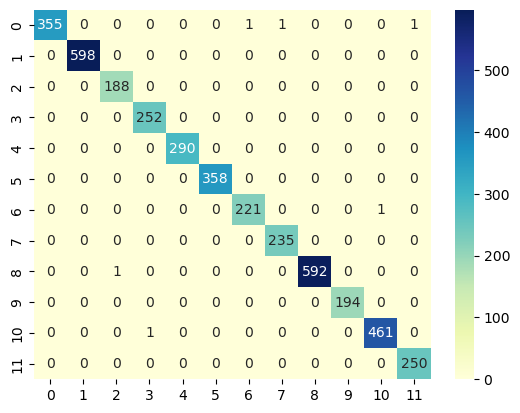

In [28]:
#tu ją wyświetlamy

#print(tarAll.shape)
#print(outAll.shape)
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(outAll.argmax(axis=1), tarAll.argmax(axis=1))
# Plot the confusion matrix
sns.heatmap(cm, annot=True,fmt='d', cmap='YlGnBu')

In [29]:
#a tu analizujemy

correct=0;
for i in range(cm.shape[0]):
    correct+=cm[i][i]
print("poprawna predykcja ", correct, " próbek")
print("błędna predykcja ",tarAll.shape[0]-correct,"próbek")

poprawna predykcja  3994  próbek
błędna predykcja  6 próbek


In [ ]:



#przygotowujemy macierz błędów (zbiór treningowy)

iter=0;
with torch.no_grad():
            suma=0.0;            
            for inputs, targets in train_loader:                
                inputs, targets = inputs.to(device), targets.to(device)                
                outputs = model(inputs)    
                o2=outputs.round()
                tar=targets.cpu().numpy();
                oo2=o2.cpu().numpy();                
                if iter==0:
                    tarAll=tar   
                    outAll=oo2;
                else:
                    tarAll=np.concatenate([tarAll,tar])
                    outAll=np.concatenate([outAll,oo2])                   
                
                iter+=1;
                #print(iter)

In [ ]:
#tu ją wyświetlamy  (zbiór treningowy)

#print(tarAll.shape)
#print(outAll.shape)
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
cm = confusion_matrix(outAll.argmax(axis=1), tarAll.argmax(axis=1))
# Plot the confusion matrix
sns.heatmap(cm, annot=True,fmt='d', cmap='YlGnBu')

In [ ]:
#a tu analizujemy

correct=0;
for i in range(cm.shape[0]):
    correct+=cm[i][i]
print("poprawna predykcja ", correct, " próbek")
print("błędna predykcja ",tarAll.shape[0]-correct,"próbek")